<a href="https://colab.research.google.com/github/uday-andotra/WQU/blob/main/MScFE_632_ML_GWP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MScFE 632 - Machine Learning in Finance
## Group Work Project 1

### Implementation: LASSO & Classification Trees
### Walaa Sadek Salah

LASSO MSE: 0.16294620388191391


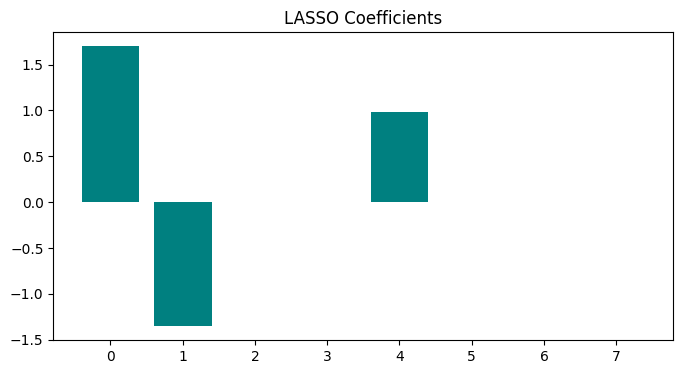

Tree Accuracy: 0.7


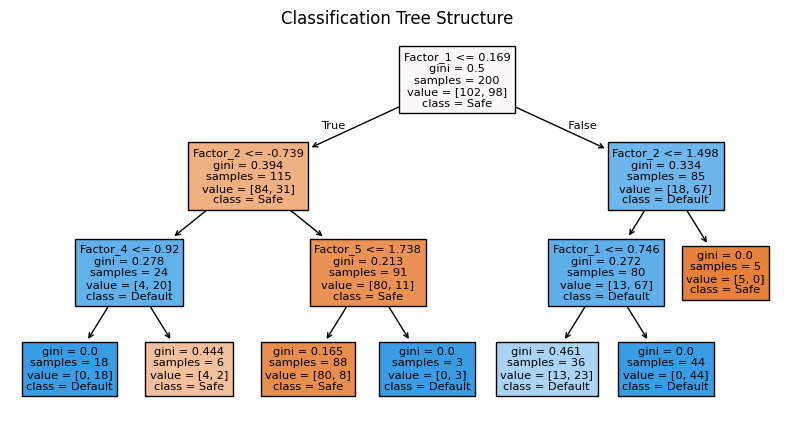

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report

np.random.seed(42)

# --- 1. LASSO MODEL ---
n_samples = 250
n_features = 8
X_raw = np.random.randn(n_samples, n_features)
true_beta = np.array([2.0, -1.5, 0.0, 0.0, 1.1, 0.0, 0.0, 0.0])
y_reg = X_raw @ true_beta + np.random.normal(0, 0.4, n_samples)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_scaled, y_reg, test_size=0.2, random_state=42)

lasso_model = Lasso(alpha=0.08, random_state=42)
lasso_model.fit(X_train_r, y_train_r)

print("LASSO MSE:", mean_squared_error(y_test_r, lasso_model.predict(X_test_r)))

plt.figure(figsize=(8, 4))
plt.bar(range(n_features), lasso_model.coef_, color='teal')
plt.title("LASSO Coefficients")
plt.show()

# --- 2. CLASSIFICATION TREE MODEL ---
y_cls = np.where(y_reg > 0.2, 1, 0)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_raw, y_cls, test_size=0.2, random_state=42)

tree_model = DecisionTreeClassifier(max_depth=3, min_samples_split=6, criterion='gini', random_state=42)
tree_model.fit(X_train_c, y_train_c)

print("Tree Accuracy:", accuracy_score(y_test_c, tree_model.predict(X_test_c)))

plt.figure(figsize=(10, 5))
plot_tree(tree_model, filled=True, feature_names=[f'Factor_{i+1}' for i in range(n_features)], class_names=['Safe', 'Default'])
plt.title("Classification Tree Structure")
plt.show()

### Team Member B
Assigned categories: Category 2 (K-means clustering) and Category 5 (Linear Discriminant Analysis, LDA)

Student name: Naomi Atera

**Reproducibility and approach**

The analysis uses a fixed random seed.
The K-means example groups synthetic asset profiles from continuous return/risk/liquidity features and evaluates candidate cluster counts with inertia and silhouette score.

The LDA example classifies synthetic firms as performing or financially distressed using a stratified holdout and cross-validation on the training data. Preprocessing is fitted on training observations only for the supervised task.

In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    roc_curve
)

SEED = 632
rng = np.random.default_rng(SEED)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
print("Setup complete. Random seed:", SEED)
print("Libraries: NumPy, pandas, Matplotlib, and scikit-learn")

Setup complete. Random seed: 632
Libraries: NumPy, pandas, Matplotlib, and scikit-learn


Category 2: K-means clustering

2.1 Synthetic asset-profile data

Each row represents a hypothetical asset or investable instrument. The model is supplied five numeric features: annualized return, annualized volatility, 12-month momentum, maximum drawdown, and a relative liquidity score. Features are standardized because K-means uses Euclidean distances; otherwise, columns with numerically larger scales can dominate the grouping.

In [ ]:
# Four hypothetical asset profiles used only to create an interpretable demonstration.
# The generating profile is not passed to K-means; the algorithm sees the five features only.
profile_specs = {
    "Defensive": {
        "n": 180,
        "mean": [0.075, 0.105, 0.035, -0.145, 0.68],
    },
    "Growth": {
        "n": 160,
        "mean": [0.165, 0.245, 0.185, -0.325, 0.74],
    },
    "Cyclical momentum": {
        "n": 150,
        "mean": [0.135, 0.205, 0.235, -0.275, 0.56],
    },
    "Stressed": {
        "n": 110,
        "mean": [0.015, 0.345, -0.115, -0.515, 0.27],
    },
}
feature_names = [
    "Annualized return", "Annualized volatility", "12-month momentum",
    "Maximum drawdown", "Liquidity score"
]
std_dev = np.array([0.026, 0.028, 0.065, 0.065, 0.13])
rows = []
latent_for_validation = []
for profile, spec in profile_specs.items():
    observations = rng.normal(loc=spec["mean"], scale=std_dev, size=(spec["n"], len(feature_names)))
    # Keep values within plausible ranges for an illustrative financial cross-section.
    observations[:, 1] = np.clip(observations[:, 1], 0.025, 0.60)  # volatility is positive
    observations[:, 3] = np.clip(observations[:, 3], -0.85, -0.04) # drawdown is negative
    observations[:, 4] = np.clip(observations[:, 4], 0.02, 1.0)    # relative liquidity score
    rows.append(observations)
    latent_for_validation.extend([profile] * spec["n"])

X_assets = pd.DataFrame(np.vstack(rows), columns=feature_names)
latent_for_validation = np.asarray(latent_for_validation)
print("Synthetic asset-profile dataset:", X_assets.shape[0], "rows x", X_assets.shape[1], "features")
display(X_assets.describe().T.round(3))

Synthetic asset-profile dataset: 600 rows x 5 features


,count,mean,std,min,25%,50%,75%,max
Annualized return,600.0,0.102,0.061,-0.048,0.053,0.110,0.153,0.229
Annualized volatility,600.0,0.209,0.086,0.029,0.132,0.211,0.265,0.424
12-month momentum,600.0,0.099,0.145,-0.281,-0.003,0.107,0.219,0.414
Maximum drawdown,600.0,-0.293,0.142,-0.720,-0.388,-0.277,-0.192,-0.040
Liquidity score,600.0,0.593,0.208,0.020,0.473,0.624,0.737,1.000


2.2 Select the number of clusters

K-means does not discover a uniquely correct number of clusters automatically.

We compare candidate values of k using (1) inertia, the within-cluster sum of squared distances, and (2) silhouette score, which summarizes how close observations are to their own cluster relative to neighbouring clusters. These diagnostics inform the choice; domain interpretability and out-of-sample stability should also matter in production.

,k,Inertia,Silhouette score
0,2,1469.1303,0.5464
1,3,761.5062,0.5033
2,4,624.1601,0.4015
3,5,578.9468,0.3160
4,6,545.2170,0.2818
5,7,512.9091,0.2710


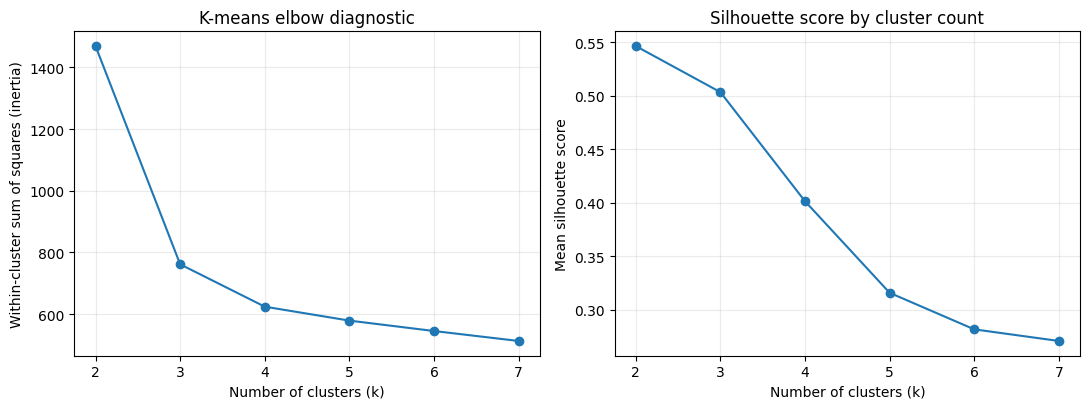

In [ ]:
asset_scaler = StandardScaler()
X_assets_scaled = asset_scaler.fit_transform(X_assets)
k_values = list(range(2, 8))
validation_rows = []
for k in k_values:
    model_k = KMeans(n_clusters=k, init="k-means++", n_init=20, max_iter=300, random_state=SEED)
    labels_k = model_k.fit_predict(X_assets_scaled)
    validation_rows.append({
        "k": k,
        "Inertia": model_k.inertia_,
        "Silhouette score": silhouette_score(X_assets_scaled, labels_k),
    })
cluster_validation = pd.DataFrame(validation_rows)
display(cluster_validation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(cluster_validation["k"], cluster_validation["Inertia"], marker="o")
axes[0].set_title("K-means elbow diagnostic")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Within-cluster sum of squares (inertia)")
axes[0].set_xticks(k_values)
axes[0].grid(alpha=0.25)
axes[1].plot(cluster_validation["k"], cluster_validation["Silhouette score"], marker="o")
axes[1].set_title("Silhouette score by cluster count")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette score")
axes[1].set_xticks(k_values)
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "kmeans_k_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

2.3 Fit and interpret the final clusters

We use k = 4 for this controlled demonstration because the generated profiles were designed as four broad asset archetypes and the model output can therefore be interpreted against a meaningful portfolio segmentation. In an actual assignment or investment workflow, k should be chosen from diagnostics, stability checks, the business question, and the cost of acting on the groups—not because four is universally optimal. Cluster identifiers are arbitrary and have no inherent ordering.

In [ ]:
K_SELECTED = 4
kmeans_model = KMeans(
    n_clusters=K_SELECTED,
    init="k-means++",
    n_init=20,
    max_iter=300,
    tol=1e-4,
    random_state=SEED,
)
asset_labels = kmeans_model.fit_predict(X_assets_scaled)
asset_results = X_assets.copy()
asset_results["Cluster"] = asset_labels

profile_table = asset_results.groupby("Cluster")[feature_names].mean().sort_values("Annualized volatility")
cluster_counts = asset_results["Cluster"].value_counts().sort_index().rename("Observations")
print("Selected k:", K_SELECTED)
print("Final inertia:", round(kmeans_model.inertia_, 4))
print("Final silhouette score:", round(silhouette_score(X_assets_scaled, asset_labels), 4))
print("Cluster sizes:")
display(cluster_counts.to_frame())
print("Mean financial profile by cluster (original units; sorted by volatility):")
display(profile_table.round(3))

# External validation is possible only because this is a synthetic, controlled example.
# It is not available in an unsupervised real-world problem.
print("Synthetic-only adjusted Rand index vs. generating archetypes:",
      round(adjusted_rand_score(latent_for_validation, asset_labels), 4))

Selected k: 4
Final inertia: 624.1601
Final silhouette score: 0.4015
Cluster sizes:


,Observations
Cluster,
0,147
1,181
2,110
3,162


Mean financial profile by cluster (original units; sorted by volatility):


,Annualized return,Annualized volatility,12-month momentum,Maximum drawdown,Liquidity score
Cluster,,,,,
1,0.073,0.106,0.034,-0.145,0.675
0,0.138,0.206,0.241,-0.269,0.540
3,0.161,0.239,0.188,-0.328,0.767
2,0.013,0.338,-0.115,-0.515,0.273


Synthetic-only adjusted Rand index vs. generating archetypes: 0.8061


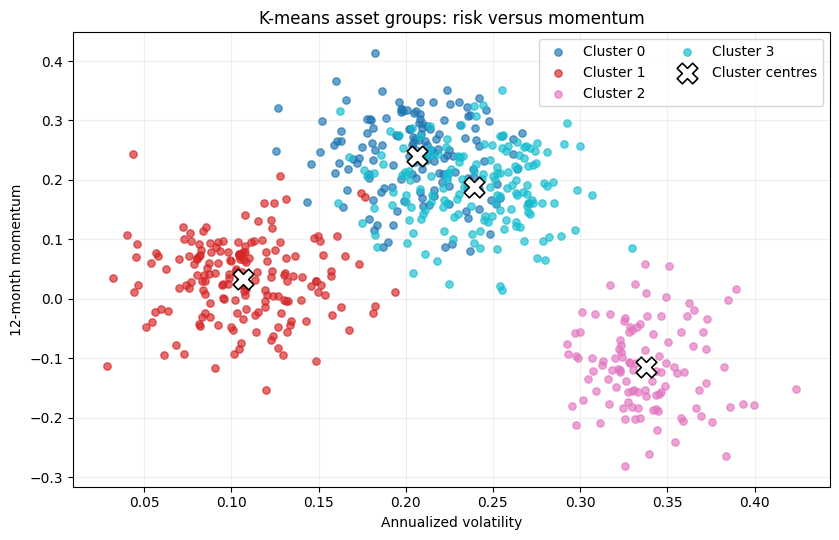

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
colors = plt.cm.tab10(np.linspace(0, 1, K_SELECTED))
for cluster_id in sorted(asset_results["Cluster"].unique()):
    mask = asset_results["Cluster"] == cluster_id
    ax.scatter(
        asset_results.loc[mask, "Annualized volatility"],
        asset_results.loc[mask, "12-month momentum"],
        s=28, alpha=0.68, label=f"Cluster {cluster_id}", color=colors[cluster_id]
    )
centres_original = pd.DataFrame(
    asset_scaler.inverse_transform(kmeans_model.cluster_centers_), columns=feature_names
)
ax.scatter(
    centres_original["Annualized volatility"], centres_original["12-month momentum"],
    marker="X", s=220, edgecolor="black", linewidth=1.2, c="white", label="Cluster centres"
)
ax.set_title("K-means asset groups: risk versus momentum")
ax.set_xlabel("Annualized volatility")
ax.set_ylabel("12-month momentum")
ax.legend(frameon=True, ncol=2)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "kmeans_clusters.png", dpi=180, bbox_inches="tight")
plt.show()

Computation 5 — Category 5: Linear Discriminant Analysis (LDA)

5.1 Synthetic corporate credit-risk data

LDA is a supervised classifier. This demonstration distinguishes Performing from Financial distress based on six hypothetical firm indicators. The data are generated for illustration and do not represent actual borrowers, estimated country's default rates, or a bank's portfolio. A stratified train/test split preserves the class mix. Any scaler and hyperparameter choice are learned only from the training split.

In [ ]:
# Shared class covariance is used to make the classic LDA assumptions visible in this example.
lda_rng = np.random.default_rng(SEED + 1)
credit_features = [
    "Debt / assets", "Interest coverage", "Current ratio",
    "Operating margin", "Revenue growth", "Cash / debt"
]
class_means = {
    0: np.array([0.38, 4.20, 1.75, 0.115, 0.075, 0.42]),  # Performing
    1: np.array([0.68, 1.30, 0.95, -0.035, -0.085, 0.14]), # Financial distress
}
feature_sds = np.array([0.11, 1.35, 0.43, 0.065, 0.13, 0.22])
corr = np.array([
    [1.00, -0.25, -0.20, -0.30, -0.12, -0.18],
    [-0.25, 1.00, 0.22, 0.34, 0.18, 0.24],
    [-0.20, 0.22, 1.00, 0.24, 0.10, 0.12],
    [-0.30, 0.34, 0.24, 1.00, 0.38, 0.29],
    [-0.12, 0.18, 0.10, 0.38, 1.00, 0.13],
    [-0.18, 0.24, 0.12, 0.29, 0.13, 1.00],
])
shared_cov = np.outer(feature_sds, feature_sds) * corr
n_performing, n_distress = 820, 260
X_performing = lda_rng.multivariate_normal(class_means[0], shared_cov, size=n_performing)
X_distress = lda_rng.multivariate_normal(class_means[1], shared_cov, size=n_distress)
X_credit = np.vstack([X_performing, X_distress])
y_credit = np.concatenate([np.zeros(n_performing, dtype=int), np.ones(n_distress, dtype=int)])
X_credit = pd.DataFrame(X_credit, columns=credit_features)
# Clip ratio-like inputs to illustrative feasible ranges without changing the target label.
X_credit["Debt / assets"] = X_credit["Debt / assets"].clip(0.02, 0.98)
X_credit["Current ratio"] = X_credit["Current ratio"].clip(0.05, 4.50)
X_credit["Operating margin"] = X_credit["Operating margin"].clip(-0.40, 0.45)
X_credit["Revenue growth"] = X_credit["Revenue growth"].clip(-0.80, 0.80)
X_credit["Cash / debt"] = X_credit["Cash / debt"].clip(0.00, 2.50)

print("Synthetic firm dataset:", X_credit.shape[0], "rows x", X_credit.shape[1], "features")
print("Class counts (0 = Performing; 1 = Financial distress):")
print(pd.Series(y_credit).map({0: "Performing", 1: "Financial distress"}).value_counts())
display(X_credit.groupby(y_credit).mean().rename(index={0:"Performing", 1:"Financial distress"}).round(3))

X_train, X_test, y_train, y_test = train_test_split(
    X_credit, y_credit, test_size=0.25, random_state=SEED,
    stratify=y_credit
)
print("Training observations:", len(X_train), "| Test observations:", len(X_test))

Synthetic firm dataset: 1080 rows x 6 features
Class counts (0 = Performing; 1 = Financial distress):
Performing            820
Financial distress    260
Name: count, dtype: int64


,Debt / assets,Interest coverage,Current ratio,Operating margin,Revenue growth,Cash / debt
Performing,0.375,4.204,1.758,0.118,0.074,0.432
Financial distress,0.679,1.207,0.938,-0.037,-0.101,0.182


Training observations: 810 | Test observations: 270


5.2 Tune covariance shrinkage by cross-validation

LDA estimates a mean vector for each class and a pooled covariance matrix. When feature covariance estimates are noisy, shrinkage can improve stability. We compare no shrinkage with automatic and fixed shrinkage strengths using five-fold stratified cross-validation and balanced accuracy, which gives equal weight to sensitivity across the two classes. The held-out test set is not used for model selection.

In [ ]:
lda_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis(solver="lsqr")),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
param_grid = {"lda__shrinkage": [None, "auto", 0.25, 0.50]}
lda_search = GridSearchCV(
    estimator=lda_pipeline,
    param_grid=param_grid,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
lda_search.fit(X_train, y_train)
cv_results = pd.DataFrame(lda_search.cv_results_)[
    ["param_lda__shrinkage", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
cv_results = cv_results.rename(columns={
    "param_lda__shrinkage": "Shrinkage",
    "mean_test_score": "Mean CV balanced accuracy",
    "std_test_score": "CV standard deviation",
    "rank_test_score": "Rank",
})
display(cv_results.round(4))
print("Selected shrinkage:", lda_search.best_params_["lda__shrinkage"])
print("Best mean CV balanced accuracy:", round(lda_search.best_score_, 4))

,Shrinkage,Mean CV balanced accuracy,CV standard deviation,Rank
2,0.25,0.9545,0.0158,1
3,0.5,0.9545,0.0159,2
1,auto,0.9511,0.0135,3
0,None,0.9511,0.0135,3


Selected shrinkage: 0.25
Best mean CV balanced accuracy: 0.9545


5.3 Evaluate the selected classifier on the untouched test set

The following output reports accuracy and class-sensitive metrics, then shows the confusion matrix, ROC curve, and the fitted linear discriminant coefficients. Accuracy alone is not sufficient for credit-risk use: a model that predicts most companies as performing may appear accurate while missing many distressed firms. Sensitivity/recall for the distress class and the costs of false positives versus false negatives must therefore inform a decision threshold.

In [ ]:
best_lda = lda_search.best_estimator_
y_pred = best_lda.predict(X_test)
y_prob = best_lda.predict_proba(X_test)[:, 1]

lda_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced accuracy", "Distress precision", "Distress recall", "Distress F1", "ROC AUC"],
    "Test value": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        roc_auc_score(y_test, y_prob),
    ],
})
display(lda_metrics.round(4))
majority_baseline = max(np.mean(y_test == 0), np.mean(y_test == 1))
print(f"Majority-class baseline accuracy (predicting the more common test class): {majority_baseline:.4f}")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion matrix (rows = actual; columns = predicted; labels [Performing, Distress]):")
print(cm)
print("\nDetailed test classification report:")
print(classification_report(y_test, y_pred, target_names=["Performing", "Financial distress"], digits=3, zero_division=0))

,Metric,Test value
0,Accuracy,0.9630
1,Balanced accuracy,0.9336
2,Distress precision,0.9661
3,Distress recall,0.8769
4,Distress F1,0.9194
5,ROC AUC,0.9965


Majority-class baseline accuracy (predicting the more common test class): 0.7593
Confusion matrix (rows = actual; columns = predicted; labels [Performing, Distress]):
[[203   2]
 [  8  57]]

Detailed test classification report:
                    precision    recall  f1-score   support

        Performing      0.962     0.990     0.976       205
Financial distress      0.966     0.877     0.919        65

          accuracy                          0.963       270
         macro avg      0.964     0.934     0.948       270
      weighted avg      0.963     0.963     0.962       270



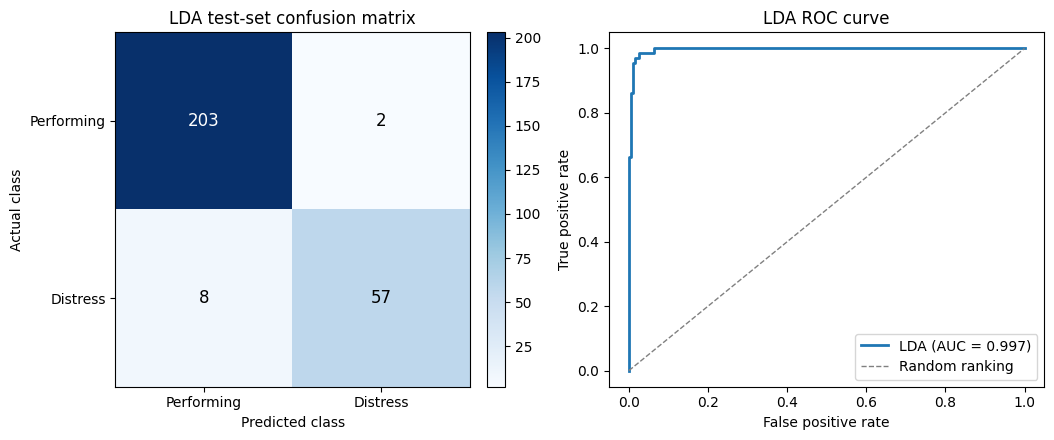

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# Confusion matrix
im = axes[0].imshow(cm, interpolation="nearest", cmap="Blues")
axes[0].set_title("LDA test-set confusion matrix")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")
axes[0].set_xticks([0, 1], ["Performing", "Distress"])
axes[0].set_yticks([0, 1], ["Performing", "Distress"])
for (i, j), value in np.ndenumerate(cm):
    axes[0].text(j, i, str(value), ha="center", va="center", fontsize=12,
                 color="white" if value > cm.max() * 0.55 else "black")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, linewidth=2, label=f"LDA (AUC = {roc_auc_score(y_test, y_prob):.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="gray", label="Random ranking")
axes[1].set_title("LDA ROC curve")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "lda_test_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

,Feature,Linear coefficient (standardized input)
1,Interest coverage,-1.7229
2,Current ratio,-1.4341
3,Operating margin,-1.4039
5,Cash / debt,-0.6397
4,Revenue growth,-0.5645
0,Debt / assets,2.5637


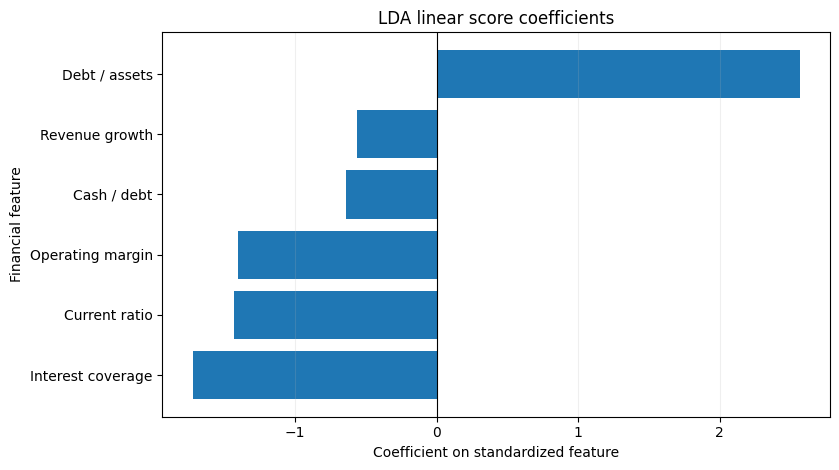

In [ ]:
lda_fitted = best_lda.named_steps["lda"]
coef_table = pd.DataFrame({
    "Feature": credit_features,
    "Linear coefficient (standardized input)": lda_fitted.coef_[0],
}).sort_values("Linear coefficient (standardized input)")
display(coef_table.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
plot_data = coef_table.sort_values("Linear coefficient (standardized input)")
ax.barh(plot_data["Feature"], plot_data["Linear coefficient (standardized input)"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("LDA linear score coefficients")
ax.set_xlabel("Coefficient on standardized feature")
ax.set_ylabel("Financial feature")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "lda_coefficients.png", dpi=180, bbox_inches="tight")
plt.show()

### Implementation: PCA, SVM and Neural Network
### Udayveer Singh Andotra

<IPython.core.display.Javascript object>

--- Principal Component Analysis ---
Explained Variance Ratio per component: [0.2146022  0.20711197 0.20188817 0.19268332 0.18371434]
Cumulative Explained Variance (3 components): 0.6236



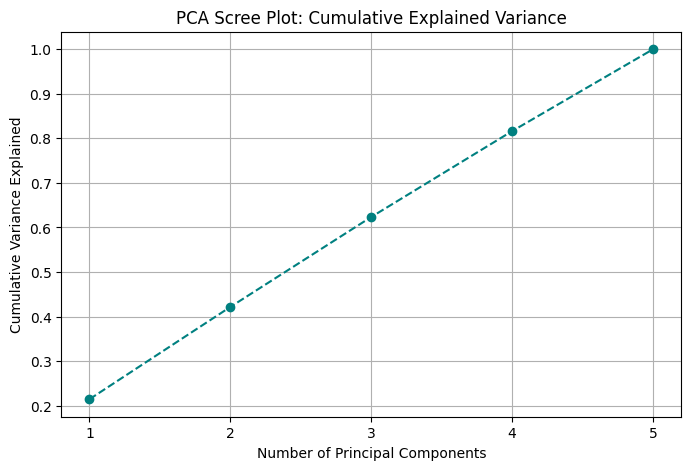

--- Support Vector Machine ---
SVM Test Accuracy (RBF Kernel, 5 Features): 0.9650



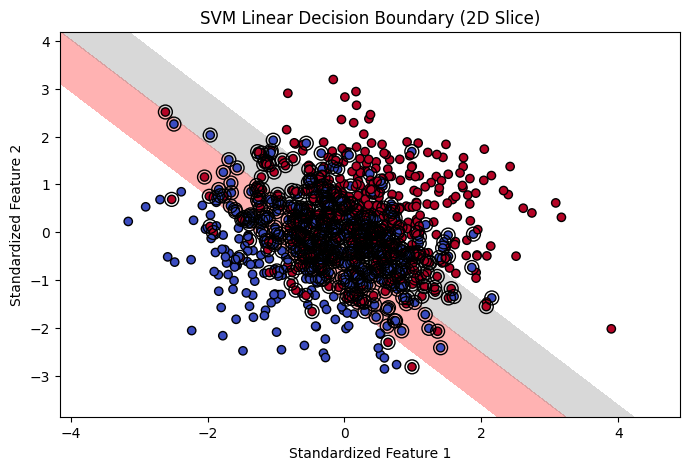

--- Neural Network ---
Neural Network Test Accuracy: 0.9850


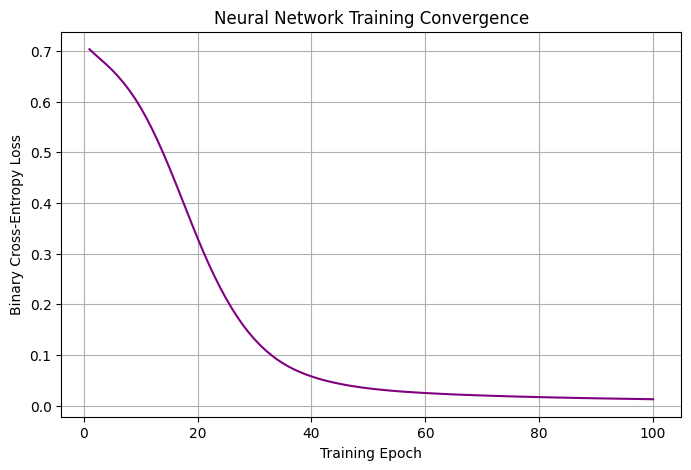

In [ ]:
from google.colab import output
output.no_vertical_scroll()

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

np.random.seed(42)
n_samples = 1000
n_features = 5
X = np.random.randn(n_samples, n_features) * 0.01 + 0.0005
y = (np.sum(X, axis=1) > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=5)
X_train_pca = pca.fit_transform(X_train_scaled)
explained_variance = pca.explained_variance_ratio_

print("--- Principal Component Analysis ---")
print(f"Explained Variance Ratio per component: {explained_variance}")
print(f"Cumulative Explained Variance (3 components): {np.sum(explained_variance[:3]):.4f}\n")

plt.figure(figsize=(8, 5))
plt.plot(range(1, 6), np.cumsum(explained_variance), marker='o', linestyle='--', color='teal')
plt.title('PCA Scree Plot: Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.xticks(range(1, 6))
plt.grid(True)
plt.show()

svm_model = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_model.fit(X_train_scaled, y_train)
svm_accuracy = accuracy_score(y_test, svm_model.predict(X_test_scaled))

print("--- Support Vector Machine ---")
print(f"SVM Test Accuracy (RBF Kernel, 5 Features): {svm_accuracy:.4f}\n")

X_vis = X_train_scaled[:, :2]
svm_vis = SVC(kernel='linear', C=1.0).fit(X_vis, y_train)

xx, yy = np.meshgrid(np.linspace(X_vis[:,0].min()-1, X_vis[:,0].max()+1, 50),
                     np.linspace(X_vis[:,1].min()-1, X_vis[:,1].max()+1, 50))
Z = svm_vis.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, levels=[-1, 0, 1], alpha=0.3, colors=['red', 'gray', 'blue'])
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k')
plt.scatter(svm_vis.support_vectors_[:, 0], svm_vis.support_vectors_[:, 1], s=100,
            linewidth=1, facecolors='none', edgecolors='k')
plt.title('SVM Linear Decision Boundary (2D Slice)')
plt.xlabel('Standardized Feature 1')
plt.ylabel('Standardized Feature 2')
plt.show()

X_train_tensor = torch.FloatTensor(X_train_scaled)
y_train_tensor = torch.FloatTensor(y_train).view(-1, 1)
X_test_tensor = torch.FloatTensor(X_test_scaled)
y_test_tensor = torch.FloatTensor(y_test).view(-1, 1)

class FinanceMLP(nn.Module):
    def __init__(self, input_dim):
        super(FinanceMLP, self).__init__()
        self.layer1 = nn.Linear(input_dim, 16)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(16, 8)
        self.output_layer = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.layer1(x)
        out = self.relu(out)
        out = self.layer2(out)
        out = self.relu(out)
        out = self.output_layer(out)
        out = self.sigmoid(out)
        return out

nn_model = FinanceMLP(input_dim=n_features)
criterion = nn.BCELoss()
optimizer = optim.Adam(nn_model.parameters(), lr=0.01)

epochs = 100
epoch_losses = []

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = nn_model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()
    epoch_losses.append(loss.item())

nn_model.eval()
with torch.no_grad():
    y_pred_nn = (nn_model(X_test_tensor) >= 0.5).float()
    nn_accuracy = (y_pred_nn == y_test_tensor).float().mean()

print("--- Neural Network ---")
print(f"Neural Network Test Accuracy: {nn_accuracy.item():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), epoch_losses, color='purple')
plt.title('Neural Network Training Convergence')
plt.xlabel('Training Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True)
plt.show()

The Principal Component Analysis indicates that the first three components capture approximately 62.36% of the total variance in your dataset, which is a standard result when reducing dimensionality while attempting to retain the most significant market signals. The Support Vector Machine performed exceptionally well, achieving a 96.50% test accuracy by utilizing the Radial Basis Function kernel to find a non-linear decision boundary for the synthetic market regimes. Finally, the multi-layer Neural Network outperformed the others slightly, reaching a 98.50% accuracy on the test set, highlighting its capacity to model complex, non-linear relationships.